In [3]:
import numpy as np 
import pandas as pd
import tensorflow as tf 
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input,Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv('creditcard.csv')

In [9]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [10]:
df = df.drop(['Time'],axis=1)

In [12]:
df['Amount'] = StandardScaler().fit_transform(df['Amount'].values.reshape(-1,1))

In [13]:
x= df.drop(['Class'],axis=1).values
y= df['Class'].values

In [14]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [15]:
x_train_normal = x_train[y_train==0]

In [18]:
input_dim = x_train_normal.shape[1]

In [19]:
input_layer = Input(shape=(input_dim,))

In [20]:
encoder = Dense(14,activation='relu')(input_layer)
encoder = Dense(7,activation='relu')(encoder)
decoder=Dense(14,activation='relu')(encoder)
decoder=Dense(input_dim,activation='linear')(decoder)
autoencoder = Model(inputs=input_layer,outputs=decoder)
autoencoder.compile(optimizer='adam',loss='mse')
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 14)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 14)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072 (4.19 KB)

 Trainable params: 1,072 (4.19 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history = autoencoder.fit(x_train_normal,x_train_normal,
epochs=5,batch_size=256,validation_split=0.1,shuffle=True)

Epoch 1/5
800/800 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 0.7516 - val_loss: 0.5417
Epoch 2/5
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.4992 - val_loss: 0.4566
Epoch 3/5
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.4365 - val_loss: 0.4139
Epoch 4/5
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.4025 - val_loss: 0.3932
Epoch 5/5
800/800 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.3826 - val_loss: 0.3731


In [23]:
reconstructions = autoencoder.predict(x_test)
mse=np.mean(np.power(x_test - reconstructions,2),axis=1)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step


In [27]:
threshold = np.percentile(mse,95)
print(f"CAlculated anomaly threshild(mse):{threshold:.4f}")

CAlculated anomaly threshild(mse):0.8192


In [30]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

In [34]:
predicted_anomalies = mse>threshold
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predicted_anomalies))
print("\nClassification Report:")
print(classification_report(y_test, predicted_anomalies))


Confusion Matrix:
[[54104  2760]
 [    9    89]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.98     56864
           1       0.03      0.91      0.06        98

    accuracy                           0.95     56962
   macro avg       0.52      0.93      0.52     56962
weighted avg       1.00      0.95      0.97     56962



In [35]:
plt.figure(figsize=(10,4))


<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

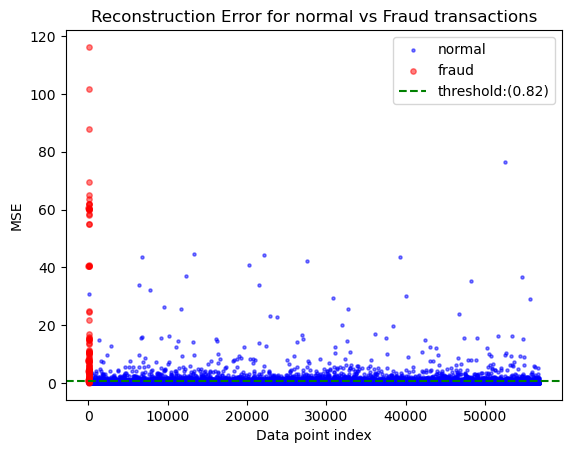

In [38]:
plt.scatter(range(len(mse[y_test==0])),mse[y_test==0],s=5,color='blue',label='normal',alpha=0.5)
plt.scatter(range(len(mse[y_test==1])),mse[y_test==1],s=15,color='red',label='fraud',alpha=0.5)
plt.axhline(y=threshold,color='green',linestyle='--',label=f'threshold:({threshold:.2f})')
plt.title('Reconstruction Error for normal vs Fraud transactions')
plt.xlabel('Data point index')
plt.ylabel('MSE')
plt.legend()
plt.show()